# Guía L1 — La factura de la ciudad · **Sesión 2: la CHEC aterriza en Londres**

**Cálculo Diferencial — Laboratorio computacional** · Universidad Nacional de Colombia, Sede Manizales

> La sesión 1 nos dejó una nube de miles de consumos y un movimiento: condicionar hasta que la relación se vuelva función. Hoy la nube se llena de pesos colombianos, y el movimiento se repite con plata.

**Antes de empezar:** copia propia del cuaderno, la tarea puente lista (la verificación reproducida) y **el recibo de energía de su casa** sobre la mesa.

---
## ⏸️ Momento 1 — Predecir

P4 y P5 están en la guía. **En papel, a mano.** La apuesta de P5 —¿la nube (consumo, valor) con todos los estratos revueltos pasa el test de la recta vertical?— es la protagonista de hoy. Foto al informe antes de seguir.

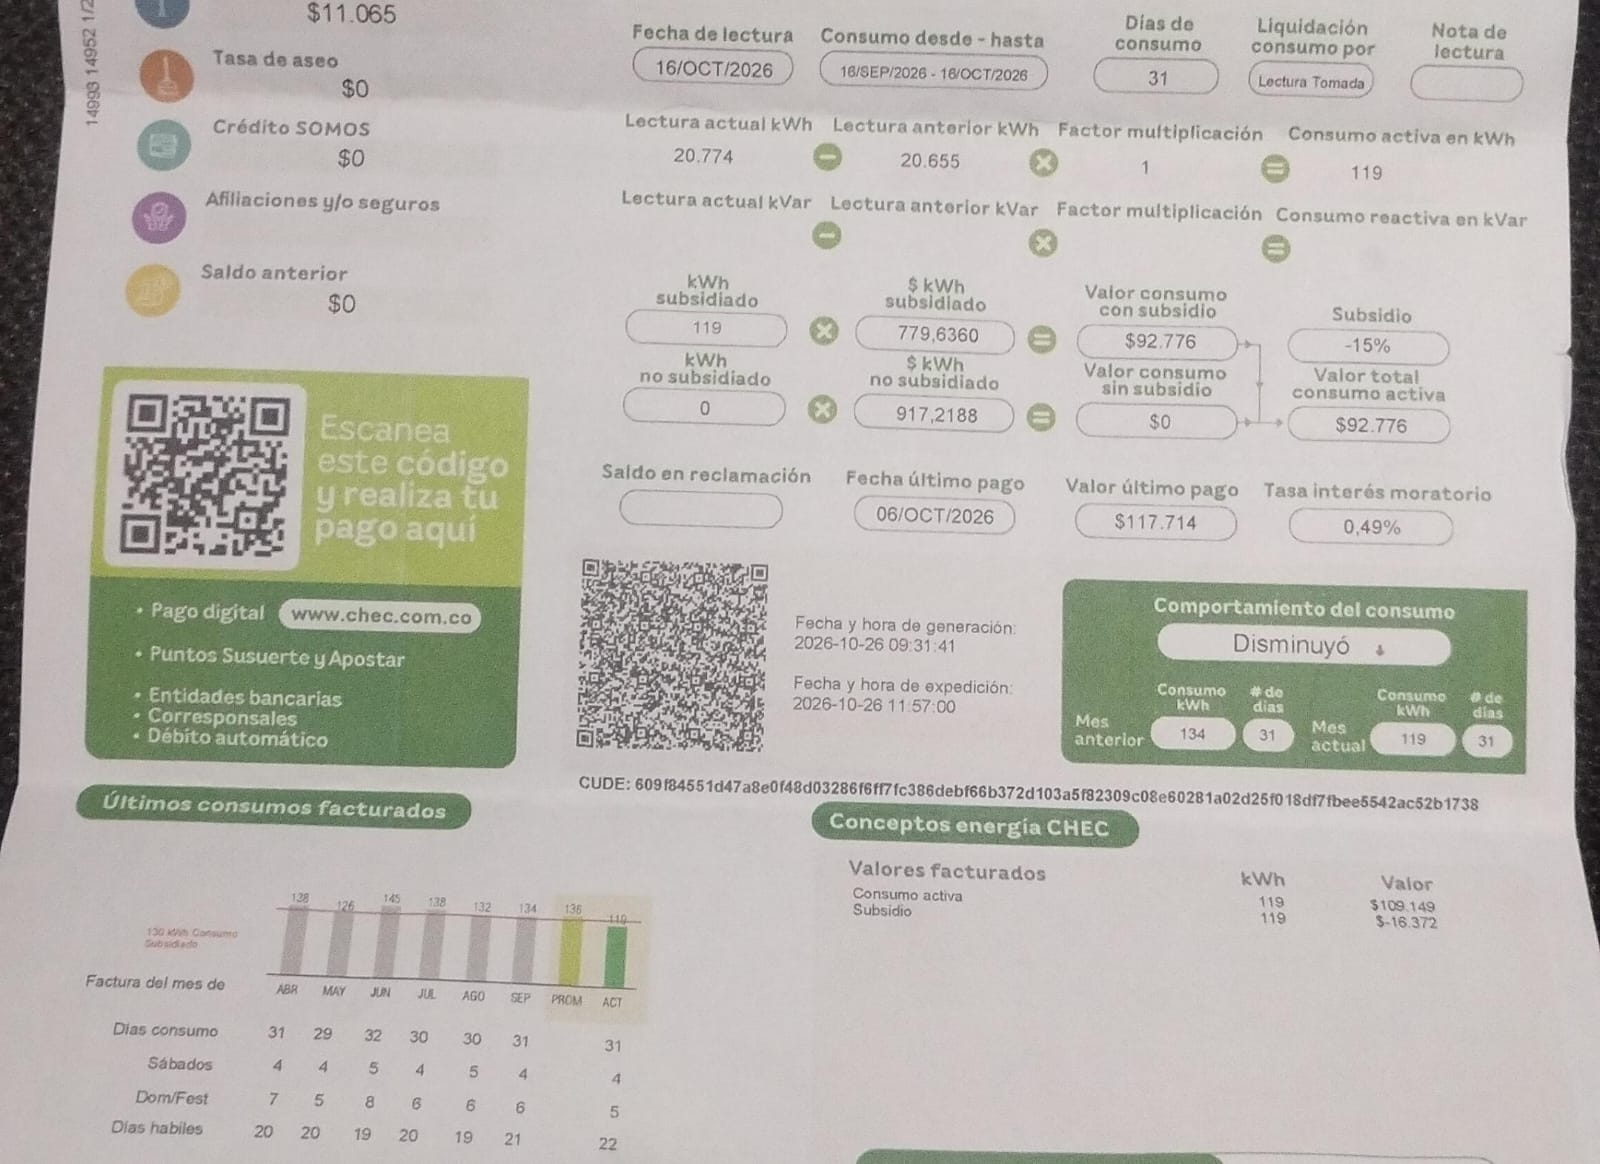

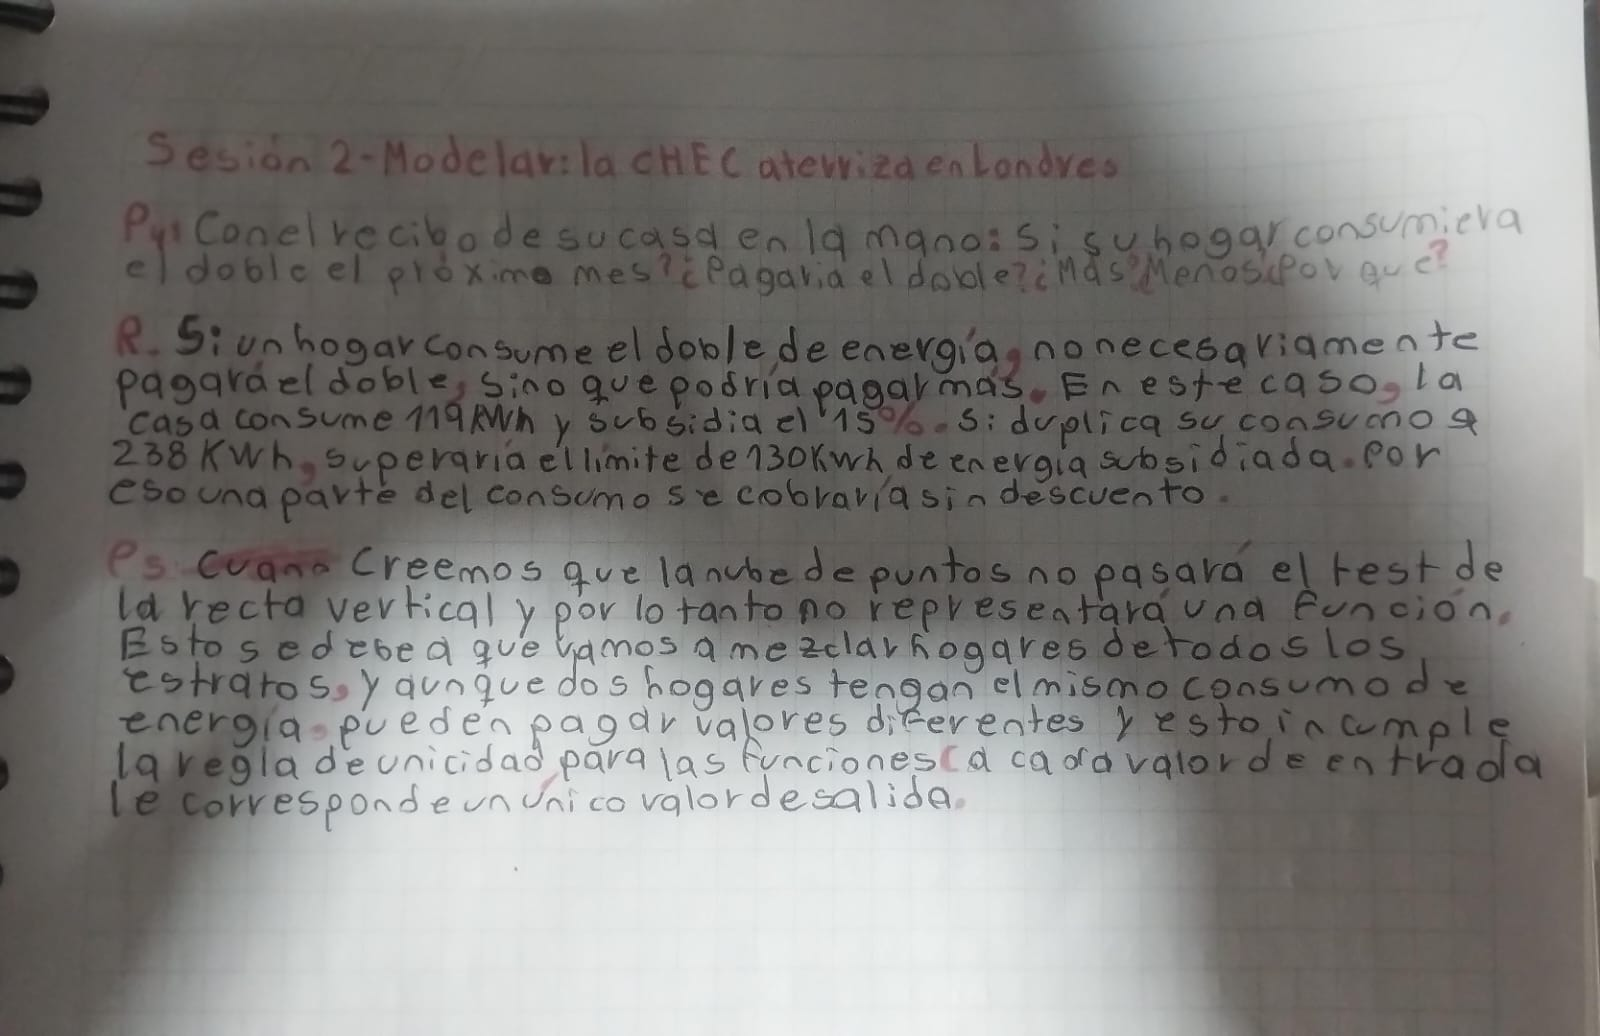

---
## 1 · La tarifa en vivo: nuestra primera API

La sesión pasada el mesero nos trajo un plato congelado. Hoy pedimos en vivo: la URL de abajo es un **pedido** al portal de datos abiertos del Estado colombiano (`datos.gov.co`), y la respuesta es el pliego tarifario oficial de la CHEC — el mismo que decide cuánto paga su casa.

Detalle de la casa: las APIs sirven porciones. Sin el `$limit`, el mesero trae solo las primeras 1.000 filas y uno ni se entera. Leer la documentación del dataset **es** parte de leer el dataset.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA_TARIFAS = "https://www.datos.gov.co/resource/c698-wqig.csv?$limit=60000"
# Si el wifi del laboratorio se cae, el monitor tiene la copia congelada (mismo formato):
# RUTA_TARIFAS = "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/main/datos/chec_tarifas_congeladas.csv"

tarifas = pd.read_csv(RUTA_TARIFAS)
print("Filas y columnas:", tarifas.shape)
print(list(tarifas.columns))

Filas y columnas: (40924, 24)
['costounitariotarifa_ano', 'costounitariotarifa_mes', 'comercializador_codigo', 'comercializador_nombre', 'mercado_codigo', 'mercado_nombre', 'costounitariotarifa_tipomed', 'nivel_tension_codigo', 'modalidadcobro_propiedad', 'claseservicio_codigo', 'claseservicio_descri', 'claseservicio_estrato', 'costounitariotarifa_rangoconsumo', 'costounitariotarifa_tipomercado', 'costounitariotarifa_generacion', 'costounitariotarifa_transmision', 'costounitariotarifa_distribucion', 'costounitariotarifa_comercializacion', 'costounitariotarifa_perdidas', 'costounitariotarifa_restricciones', 'costounitariotarifa_cu', 'costounitariotarifa_cureal', 'costounitariotarifa_subcon', 'costounitariotarifa_valor_tarifa']


mercado_nombre
CHEC       37844
PEREIRA     3080
Name: count, dtype: int64


In [ ]:
# ✏️ Ejercicio 1 — El ritual, ahora sin acompañamiento: mirar antes de cruzar.
# Este dataset tiene más columnas y más trampas que el de Londres. Respondan con código:
#   a) ¿Qué mercados (mercado_nombre) aparecen y con cuántas filas cada uno?
#   b) ¿Qué años cubre el pliego? (ojo: la columna de año puede venir como texto "2,026")
#   c) ¿Qué estratos residenciales hay y qué valores toma el "rango de consumo"?
#   d) ¿Hay NaN donde no debería haberlos? ¿Y cuál es el DOMINIO de valor_tarifa?

# Normalizamos el año y el valor de una vez:
tarifas["ano"] = tarifas["costounitariotarifa_ano"].astype(str).str.replace(",", "").astype(int)
tarifas["valor"] = pd.to_numeric(tarifas["costounitariotarifa_valor_tarifa"], errors="coerce")

print(tarifas["mercado_nombre"].value_counts())
# ... su turno con b), c), d)
# b) ¿Qué años cubre el pliego?
print(sorted(tarifas["ano"].unique()))
print("Desde", tarifas["ano"].min(), "hasta", tarifas["ano"].max())
print(tarifas["ano"].value_counts().sort_index())

# c) Estratos residenciales y rango de consumo
print(tarifas["claseservicio_descri"].value_counts(dropna=False))   # ¿qué clases de servicio hay?
print(tarifas["claseservicio_estrato"].value_counts(dropna=False))
print(tarifas["costounitariotarifa_rangoconsumo"].value_counts(dropna=False))

# Qué rangos toma cada estrato
print(tarifas.groupby("claseservicio_estrato")["costounitariotarifa_rangoconsumo"].unique())

# d) NaN y dominio de valor_tarifa
print(tarifas.isna().sum())
print(tarifas["valor"].describe())
print("Mín:", tarifas["valor"].min(), "Máx:", tarifas["valor"].max())

# NaN creados por errors="coerce" (textos que no eran números)
orig = tarifas["costounitariotarifa_valor_tarifa"]
print("Valores no numéricos:", orig[tarifas["valor"].isna() & orig.notna()].unique())

# Ceros o negativos
print("Ceros o negativos:", (tarifas["valor"] <= 0).sum())

mercado_nombre
CHEC       37844
PEREIRA     3080
Name: count, dtype: int64
[np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
Desde 2008 hasta 2026
ano
2008    2251
2009    2509
2010    1417
2011    1824
2012    1934
2013    2004
2014    2046
2015    2124
2016    2124
2017    2124
2018    2125
2019    2136
2020    2151
2021    1996
2022    1848
2023    1848
2024    1848
2025    3465
2026    3150
Name: count, dtype: int64
claseservicio_descri
Industrial               4662
Residencial Estrato 4    4588
Comercial                4573
Provisional              3708
Residencial Estrato 5    2979
Residencial Estrato 6    2931
Residencial              1818
Oficial                  1570
Especial Educativo       1218
Especial Asistencial     1218


---
## 2 · La tarifa como función: `valor_factura`

Del pliego a la **función definida por trozos** que decide cuánto paga una casa. Dos ingredientes reales:

- El **consumo de subsistencia** (CS): en Manizales (2.150 m; la norma fija el umbral en 1.000 m de altitud) son **130 kWh/mes** (173 kWh/mes por debajo de los 1.000 m). Hasta ahí, los estratos 1–3 pagan tarifa subsidiada; de ahí en adelante, todos pagan tarifa plena. Búsquenlo en su recibo.
- El **pliego del mes**: lo sacamos del dataset, no de un número inventado. (El pliego trae variantes por propiedad de la red y nivel de tensión; tomamos las condiciones más comunes y la *mediana* cuando queda más de un valor — decisión de modelación, y queda escrita.)

Escriban la función en notación de la clase antes de leer el código: para estrato $e \le 3$,

$$V_e(x) = \begin{cases} t^{sub}_e \, x & 0 \le x \le CS \\ t^{sub}_e \, CS + t^{pl}\,(x - CS) & x > CS \end{cases}$$

¿Y para $e \ge 4$? ¿Es continua $V_e$ en $x = CS$? ¿Es derivable ahí? (Guarden la segunda pregunta: vuelve en el curso.)

In [ ]:
ANO_TARIFA, MES_TARIFA = 2026, 8   # el pliego que usaremos para cobrar (el más reciente)
CS = 130                            # kWh/mes de subsistencia para alturas >= 1000 m (Manizales: 2.150 m)

base = tarifas[(tarifas["mercado_nombre"] == "CHEC") &
               (tarifas["costounitariotarifa_tipomercado"] == "R") &
               (tarifas["nivel_tension_codigo"] == 1) &
               (tarifas["modalidadcobro_propiedad"] == "0% OR") &
               (tarifas["ano"] == ANO_TARIFA) &
               (pd.to_numeric(tarifas["costounitariotarifa_mes"]) == MES_TARIFA) &
               (tarifas["claseservicio_descri"].str.contains("Residencial Estrato", na=False))]

pliego = base.pivot_table(index="claseservicio_estrato",
                          columns="costounitariotarifa_rangoconsumo",
                          values="valor", aggfunc="median")
pliego.columns = ["subsidiada", "plena"][:len(pliego.columns)]
print("Pliego CHEC", ANO_TARIFA, "-", MES_TARIFA, "($/kWh):")
print(pliego.round(2))

def valor_factura(kwh, estrato):
    """Valor de la energía de un mes (sin cargo fijo, sin alumbrado): función por trozos."""
    t_sub = pliego.loc[estrato, "subsidiada"]
    t_plena = pliego.loc[estrato, "plena"] if not pd.isna(pliego.loc[estrato].get("plena", np.nan)) else t_sub
    if estrato <= 3:
        basico = min(kwh, CS) * t_sub       # el tramo subsidiado, hasta el CS
        resto  = max(kwh - CS, 0) * t_plena  # el resto, a tarifa plena
        return basico + resto
    else:
        return kwh * t_sub                   # estratos 4-6: un solo precio (4: pleno; 5-6: con contribución)

for kwh in [100, 130, 200, 300]:
    print(f"Estrato 3, {kwh} kWh → ${valor_factura(kwh, 3):,.0f}")

Pliego CHEC 2026 - 8 ($/kWh):
                       subsidiada   plena
claseservicio_estrato                    
1.0                        422.62  894.58
2.0                        528.28  894.58
3.0                        760.40  894.58
4.0                        894.58     NaN
5.0                       1073.50     NaN
6.0                       1073.50     NaN
Estrato 3, 100 kWh → $76,040
Estrato 3, 130 kWh → $98,852
Estrato 3, 200 kWh → $161,473
Estrato 3, 300 kWh → $250,931


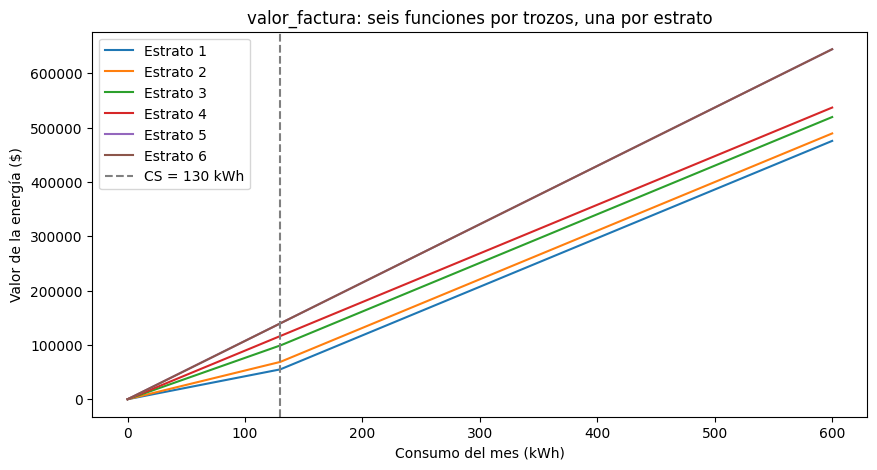

In [ ]:
# Seis curvas, una por estrato: la función por trozos, dibujada.
x = np.linspace(0, 600, 601)
plt.figure(figsize=(10, 5))
for e in range(1, 7):
    plt.plot(x, [valor_factura(k, e) for k in x], label=f"Estrato {e}")
plt.axvline(CS, linestyle="--", color="gray", label=f"CS = {CS} kWh")
plt.xlabel("Consumo del mes (kWh)"); plt.ylabel("Valor de la energía ($)")
plt.title("valor_factura: seis funciones por trozos, una por estrato")
plt.legend(); plt.show()

# 🗣️ ¿En qué estratos hay un 'codo' y en cuáles no? ¿Qué pasa con la pendiente antes y después del CS?

In [ ]:
# ✏️ Ejercicio 2 — La auditoría del recibo.
# Con el recibo de un integrante: consumo del mes (kWh), estrato, y valor pagado por ENERGÍA.
kwh_recibo   = 119     # ← su recibo
estrato_casa = 3     # ← su estrato
pago_real    = 92777     # ← lo que dice el recibo

print(f"El modelo dice: ${valor_factura(kwh_recibo, estrato_casa):,.0f}  |  El recibo dice: ${pago_real:,.0f}")

# 🗣️ ¿El modelo reproduce, aproximadamente, lo que su casa pagó? ¿Qué explica la diferencia?
#    (cargo fijo, alumbrado público, contribución, el mes del pliego...). Acaban de auditar
#    su propio modelo contra la realidad — anoten el veredicto.
# El modelo da un valor un cercano a lo que se pago en la casa de mi compañero, como se aprecia al ejecutar el código la diferencia es de 19016 pesos.
# Esta diferencia explica que el modelo solo calcula el valor puro de la energía consumida.
# El recibo físico incluye cobros y tasas adicionales, tenemos el alumbrado público con un costo de 16837 pesos y un apartado
# llamado Otros conceptos energía CHEC con valor de 74 pesos.

El modelo dice: $90,487  |  El recibo dice: $92,777


---
## 3 · La decisión de modelación: ¿qué estrato le toca a Londres?

Para cobrarle a un hogar londinense necesitamos asignarle un estrato — y eso es **supuesto nuestro**, no dato. Abajo hay un criterio de ejemplo (cuantiles de consumo, con proporciones parecidas a las de Manizales). Su equipo puede adoptarlo o cambiarlo, pero sea cual sea el criterio: **se defiende por escrito en tres líneas**. No hay criterio “correcto”; hay criterios defendibles y criterios que no se pensaron.

In [ ]:
# Cargamos Londres: la copia congelada de la sesión 1 (consumo MENSUAL por hogar).
RUTA = "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/main/datos/londres_mensual.csv"
df = pd.read_csv(RUTA)
print("Filas:", len(df), "| hogares:", df["hogar"].nunique())

# ✏️ Criterio de ejemplo (cámbienlo si quieren): el estrato se asigna POR HOGAR según su consumo
# mediano en todo el estudio (un hogar no cambia de estrato de un mes a otro).
consumo_hogar = df.groupby("hogar")["kwh"].median()
cortes = consumo_hogar.quantile([0, .25, .50, .70, .85, .95, 1.0]).values
estrato_hogar = pd.cut(consumo_hogar, bins=cortes, labels=[1, 2, 3, 4, 5, 6], include_lowest=True).astype(int)
df["estrato"] = df["hogar"].map(estrato_hogar)
print(estrato_hogar.value_counts().sort_index())

# 🗣️ Defensa del criterio (tres líneas, aquí): ¿por qué ESTE reparto y no otro?

Filas: 113440 | hogares: 5556
kwh
1    1389
2    1389
3    1111
4     833
5     556
6     278
Name: count, dtype: int64


---
## 4 · La nube: la ciudad facturada

Aplicamos `valor_factura` a los 113.440 pares (hogar, mes) y graficamos **(consumo, valor)**. Primero todos los estratos revueltos; relean P5 antes de correr la celda.

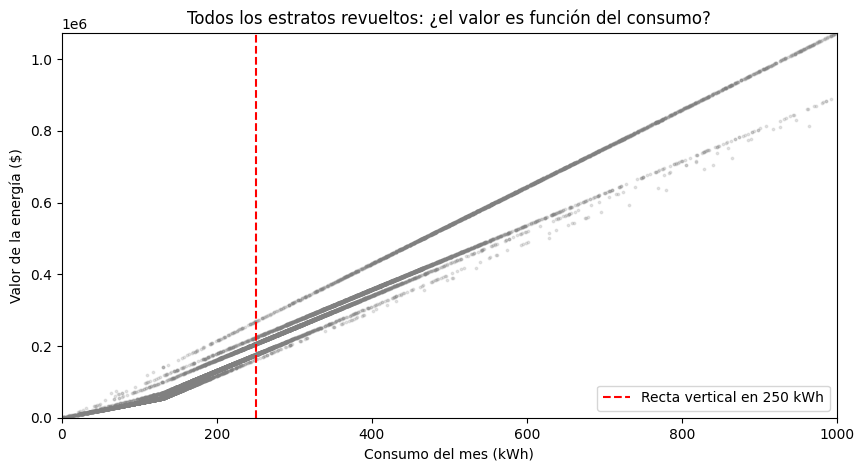

Hogares con consumo ≈ 250 kWh: 530 | valores distintos que pagan: 330
estrato
1    162363.0
2    175861.0
3    206247.0
4    223727.0
5    268848.0
6    268231.0
Name: valor, dtype: float64


In [ ]:
df["valor"] = [valor_factura(k, e) for k, e in zip(df["kwh"], df["estrato"])]

muestra = df.sample(min(20000, len(df)), random_state=1)
plt.figure(figsize=(10, 5))
plt.scatter(muestra["kwh"], muestra["valor"], s=3, alpha=0.2, color="gray")
X0 = 250
plt.axvline(X0, color="red", linestyle="--", linewidth=1.5, label=f"Recta vertical en {X0} kWh")
plt.xlim(0, 1000); plt.ylim(0, valor_factura(1000, 6))
plt.xlabel("Consumo del mes (kWh)"); plt.ylabel("Valor de la energía ($)")
plt.title("Todos los estratos revueltos: ¿el valor es función del consumo?")
plt.legend(); plt.show()

cerca = df[(df["kwh"] > X0 - 1) & (df["kwh"] < X0 + 1)]
print(f"Hogares con consumo ≈ {X0} kWh: {len(cerca)} | valores distintos que pagan: {cerca['valor'].round(0).nunique()}")
print(cerca.groupby("estrato")["valor"].median().round(0))

🗣️ **La recta roja atraviesa la nube ¿en cuántos puntos?** Un mismo consumo, varios valores. Entonces, revueltos, el valor **no** es función solo del consumo: falta una variable en el dominio. ¿Cuál? Escríbanlo con la definición formal (dominio, codominio, regla) y confronten P5.

La variable faltante es el estrato socioeconómico.

Dominio: Debe ser el producto cartesiano D = Consumo (kWh) * Estrato (x,t).

Codiminio: C = $[0, \infty)$, correspondiente al valor en pesos colombianos.

Regla: Falla la unicidad, como una misma entrada x = 250 kWh genera hasta 6 salidas distintas en el codominio según la tarifa asignada, la relación NO es función respecto al consumo.


Ahora el movimiento de la sesión 1, con plata: **condicionar por estrato**.

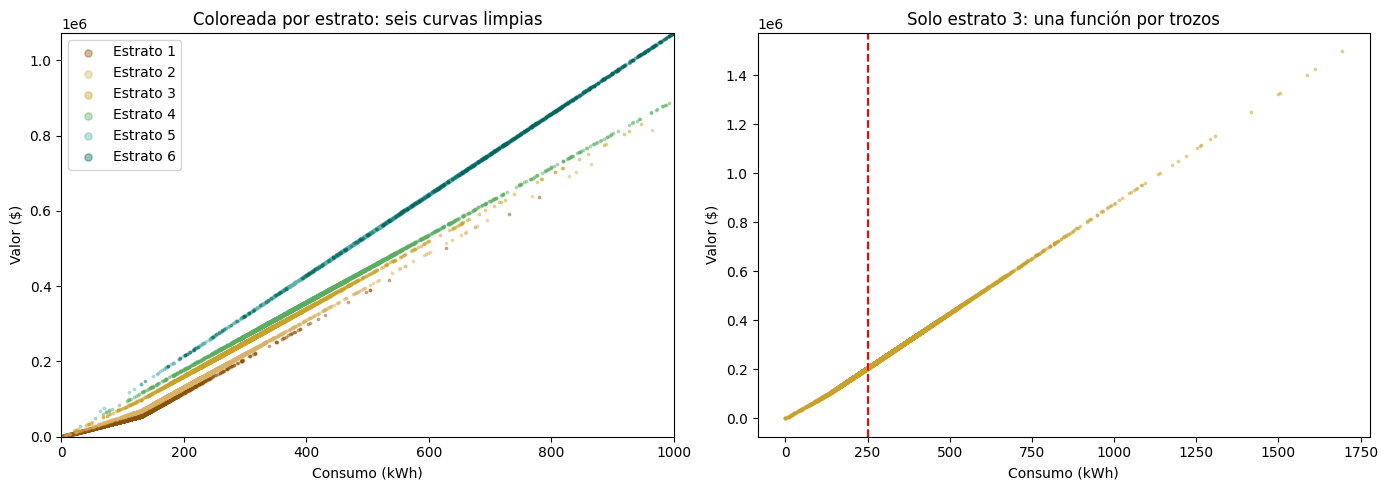

Estrato 3, consumo ≈ 250 kWh: 232 hogares, ¿cuántos valores distintos? Miren:
        kwh     valor
265   250.0  206183.9
580   249.5  205790.3
955   249.7  205906.6
1340  250.8  206935.4
1414  249.1  205405.6
3091  250.8  206881.7
4002  249.4  205656.1
4038  250.2  206345.0


In [ ]:
colores = {1: "#8c510a", 2: "#d8b365", 3: "#c9a227", 4: "#5aae61", 5: "#5ab4ac", 6: "#01665e"}
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for e in range(1, 7):
    sub = muestra[muestra["estrato"] == e]
    ax[0].scatter(sub["kwh"], sub["valor"], s=3, alpha=0.4, color=colores[e], label=f"Estrato {e}")
ax[0].set_xlim(0, 1000); ax[0].set_ylim(0, valor_factura(1000, 6))
ax[0].set_title("Coloreada por estrato: seis curvas limpias"); ax[0].legend(markerscale=3)
ax[0].set_xlabel("Consumo (kWh)"); ax[0].set_ylabel("Valor ($)")

# ✏️ Ejercicio 3 — Un solo estrato. Cambien E y comprueben con código que ahora sí es función:
E = 3
uno = df[df["estrato"] == E]
ax[1].scatter(uno["kwh"], uno["valor"], s=3, alpha=0.4, color=colores[E])
ax[1].axvline(X0, color="red", linestyle="--")
ax[1].set_title(f"Solo estrato {E}: una función por trozos")
ax[1].set_xlabel("Consumo (kWh)"); ax[1].set_ylabel("Valor ($)")
plt.tight_layout(); plt.show()

cerca_E = uno[(uno["kwh"] > X0 - 1) & (uno["kwh"] < X0 + 1)]
print(f"Estrato {E}, consumo ≈ {X0} kWh: {len(cerca_E)} hogares, ¿cuántos valores distintos? Miren:")
print(cerca_E[["kwh", "valor"]].head(8).round(1))
# 🗣️ Los valores casi coinciden pero no exactamente: ¿por qué? (Pista: 'consumo ≈ 250' no es 'consumo = 250'.)
#    ¿Qué tendrían que fijar para que la recta vertical atraviese EXACTAMENTE un punto?

🗣️ **Conclusión del movimiento, ahora con dinero:** al condicionar por estrato, la relación (consumo, valor) **se volvió** función, porque: *(dominio, codominio, regla)*.

Dominio: Todos los valores posibles de consumo mensual (kWh), $x \in [0, \infty)$.

Codominio: El valor a pagar en pesos colombianos, $y \in [0, \infty)$.

Regla: La función por trozos asigna un único valor en pesos $y$ a cada valor de consumo $x$. Al fijar el estrato, se elimina la ambiguedad tarifaria y cualquier recta vertical $x = X_0$ corta la curva en unn solo punto





Y una pregunta para el informe: ¿cuál sería el dominio correcto de $V$ si quisiéramos que fuera función *sin* condicionar? (Pista: pares.)

Para que el valor a pagar $V$ sea función matemática estricta sobre toda la ciudad junta, la función necesita dos datos de entrada para saber que+é tarifa aplicar.

Entonces, el dominio no puede ser solo un número real ($x$), sino el conjunto de pares ordenados:

$$Dominio = \{ (x, e) \mid x \ge 0, \, e \in \{1, 2, 3, 4, 5, 6\} \}$$

$x$ es el consumo de kWh.

$e$ es el estrato socioeconómico de la vivienda.


---
## 5 · Cuantificar: el mismo aumento no cuesta lo mismo

Un hogar de estrato 3 aumenta su consumo en 25 kWh. ¿Cuánto más paga? Depende de **dónde** estaba.

Estrato 3, de 100 a 125 kWh (+25 kWh): paga $19,010 más  →  $760.4 por cada kWh adicional
Estrato 3, de 135 a 160 kWh (+25 kWh): paga $22,365 más  →  $894.6 por cada kWh adicional
Estrato 3, de 120 a 145 kWh (+25 kWh): paga $21,023 más  →  $840.9 por cada kWh adicional


In [ ]:
# ✏️ Ejercicio 4 — Dos aumentos iguales, dos cobros distintos.
for a, b in [(100, 125), (135, 160), (120, 145)]:
    delta = valor_factura(b, 3) - valor_factura(a, 3)
    print(f"Estrato 3, de {a} a {b} kWh (+{b-a} kWh): paga ${delta:,.0f} más  →  ${delta/(b-a):,.1f} por cada kWh adicional")

# 🗣️ ¿Por qué no es lo mismo, si el aumento de consumo fue igual? Expliquen con los tramos y con el CS.
#    El cociente 'pesos adicionales / kWh adicional' tiene nombre en este curso: ¿cuál? ¿Es constante en cada tramo?
#    ¿Qué pasa con ese cociente en el tercer intervalo, el que CRUZA el CS? ¿Es 'la pendiente' de algo?
# En el estrato 3 la función depende del tramo:
# En (100,125), todo el aumento ocurre dentro del consumo de subsistencia (CS = 130 kWh), pagando a tarifa subsidiada.
# En (135,160), todo el incremento ocurre por encima del CS, pagando a tarifa plena.
# En (120,145), el incremento cruza la frontera del CS, los primeros 10kWh se pagan a tarifa subsidiadad y los 15 kWh restantes a tarifa plena.
# El cociente se llama Tasa de Variación Media (TVM) en el intervalo [a,b], que numéricamente corresponde a la pendiente
# de la recta secante.
# Es constante si el intervalo completo cae estrictamente dentro de un solo tramo lineal.
# En el 3er intervalo NO, porque al cruzar el CS, la TVM es un promedio ponderado de  las dos pendientes (Un tramo económico y un tramo costoso).
# Al pasar la frontera del CS = 130kWh, la TVM toma un valor intermedio. No coinciden ni con la tarifa subsidiada pura ni con la plena.
# La pendiente geométricamente si es algo, la TVM es la pendiente de la recta secante que conecta los dos puntos de la gráfica.  Al atravesar el codo de la función,
# Esa recta secante corta la esquina del quiebre en la curva.

# ✏️ Repitan para estrato 5: ¿cambia el cociente entre los dos intervalos? ¿Por qué?
print("\n--- Estrato 5 ---")
for a, b in [(100, 125), (135, 160), (120, 145)]:
    delta5 = valor_factura(b, 5) - valor_factura(a, 5)
    print(f"Estrato 5, de {a} a {b} kWh (+{b-a} kWh): paga ${delta5:,.0f} más  →  ${delta5/(b-a):,.1f} por cada kWh adicional")
# En estrato 5 no existe subsidio en el Consumo de Subsistencia (CS = 130 kWh).
# Todo el consumo se factura bajo una tarifa única continua (tarifa plena + 20% contribución).
# Al no existir un quiebre en la curva, la función es lineal en todo su dominio.
# La Tasa de Variación Media (TVM) o 'pendiente' es constante y no depende del tramo ni del intervalo considerado.

Estrato 3, de 100 a 125 kWh (+25 kWh): paga $19,010 más  →  $760.4 por cada kWh adicional
Estrato 3, de 135 a 160 kWh (+25 kWh): paga $22,365 más  →  $894.6 por cada kWh adicional
Estrato 3, de 120 a 145 kWh (+25 kWh): paga $21,023 más  →  $840.9 por cada kWh adicional

--- Estrato 5 ---
Estrato 5, de 100 a 125 kWh (+25 kWh): paga $26,838 más  →  $1,073.5 por cada kWh adicional
Estrato 5, de 135 a 160 kWh (+25 kWh): paga $26,838 más  →  $1,073.5 por cada kWh adicional
Estrato 5, de 120 a 145 kWh (+25 kWh): paga $26,838 más  →  $1,073.5 por cada kWh adicional


In [ ]:
# La matriz de correlación: la covariación resumida en un número.
numericas = df[["kwh", "valor", "estrato"]]
print(numericas.corr().round(3))

# 🗣️ ¿Qué mide la correlación entre kwh y valor? ¿Por qué es alta pero NO es 1, si dentro de cada
#    estrato el valor es función del consumo? ¿Qué NO mide la correlación? (Pista: ¿detectaría una
#    relación en forma de U?) La correlación es la covariación — nuestro concepto rector — resumida
#    en un solo valor entre -1 y 1.

           kwh  valor  estrato
kwh      1.000  0.994    0.767
valor    0.994  1.000    0.798
estrato  0.767  0.798    1.000


---
## 6 · El microdataset del curso

Cada estudiante sube **una fila** a la tabla compartida del curso: `(codigo_anonimo, mes, kwh, valor_pagado, estrato)` — su recibo, anonimizado.

🗣️ Discutan 10 minutos: ¿por qué la tabla tiene *esas* columnas y no otras? ¿Qué preguntas futuras permite responder esa estructura y cuáles cierra? Elegir la estructura de una tabla es decidir qué se va a poder preguntar — eso también es matemáticas.

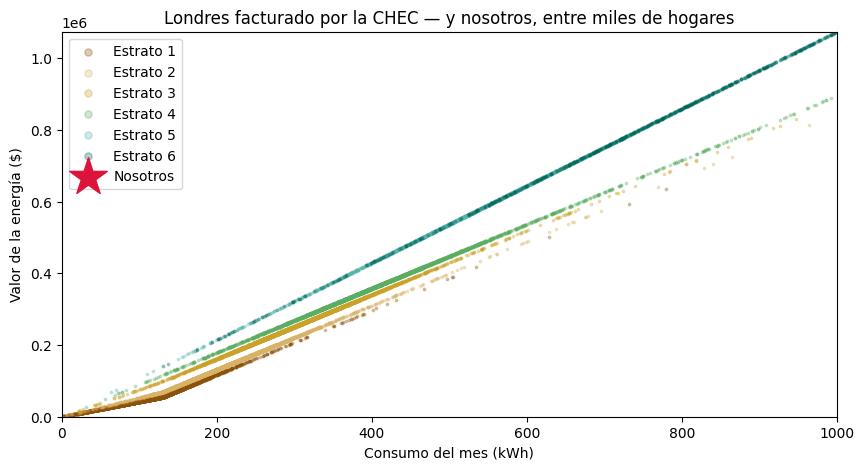

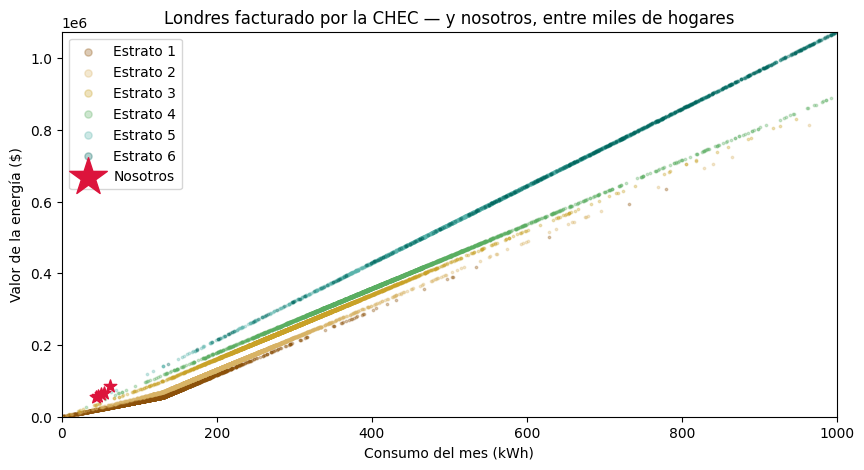

In [ ]:
# La nube final: Londres facturado por la CHEC, con nosotros adentro.
plt.figure(figsize=(10, 5))
for e in range(1, 7):
    sub = muestra[muestra["estrato"] == e]
    plt.scatter(sub["kwh"], sub["valor"], s=3, alpha=0.3, color=colores[e], label=f"Estrato {e}")

# ✏️ Los puntos del curso (llenen con las filas del microdataset — kWh y valor por energía):
curso_kwh   = [51, 54, 44, 47, 62]   # p. ej. [180, 95, 210, ...]
curso_valor = [64640, 66450, 54876, 58974, 84760]   # p. ej. [148000, 52000, 175000, ...]
plt.scatter(curso_kwh, curso_valor, s=90, marker="*", color="crimson", zorder=3, label="Nosotros")

plt.xlim(0, 1000); plt.ylim(0, valor_factura(1000, 6))
plt.xlabel("Consumo del mes (kWh)"); plt.ylabel("Valor de la energía ($)")
plt.title("Londres facturado por la CHEC — y nosotros, entre miles de hogares")
plt.legend(markerscale=3); plt.show()

# 🗣️ Ahí estamos, del otro lado del océano. ¿Nuestros puntos caen sobre la curva de su estrato? Si no, ¿por qué?
#  Al graficar nuestros datos reales (los puntos rojos con forma de estrella), se observa que NO caen
#  exactamente sobre las curvas del modelo: quedan desplazados hacia ARRIBA.
#  Esto se debe a tres razones principales:
#  Cargos fijos y rubros adicionales: Las curvas del modelo grafican únicamente el costo puro de la
#  energía activa consumida (kWh * tarifa). Los recibos reales de nuestras casas incluyen cargos fijos,
#  impuesto de Alumbrado Público y tasas de aseo, lo que eleva el valor total pagado ($).
#  Desfase en el pliego tarifario: El modelo utiliza las tarifas base fijas de la CHEC de un mes de referencia,
#  mientras que nuestras facturas reales corresponden a meses donde la tarifa $/kWh varía por inflación
#  y costos de generación.
#  Escala de consumo: Los consumos de nuestras casas (entre 44 y 62 kWh) se ubican estrictamente en el primer
#  tramo de la función por trozos, por debajo del Consumo de Subsistencia (CS = 130 kWh).

---
## 🗣️ Momento 3 — Explicar

Una página del equipo, aquí mismo: las dos discrepancias más interesantes entre predicción y resultado (P4, P5); la defensa del criterio de estratificación; y una reflexión de tres líneas sobre **qué fue real y qué fue supuesto** en todo lo que hicieron.

En P4 se predijo con mis compañeros que al consumir el doble de kWh no necesariamente se pagaria un poco menos del doble del valor del recibo, en el caso del recibo de mi compañero que estaba estratificado en el valor 3,la casa consume 119 KWH y subsidia el 15%. Si duplica su consumo a 238 KWH, superaria el limite de 130 KWH de energia subsidiada. Por eso una parte del consumo se cobraria sin descuento.

En P5 con mis compañeros dimos como predicción de que no iba a ser función ya que no iba a suplir la regla de la unicidad. Con lo visto en esta sesión la predicción fue acertada ya que la prueba de la linea vertical falla, al mezclar a toda la ciudad, la gráfica no es una función matemática porque a un mismo valor de consumo $x$ le corresponden hasta 6 valores distintos de cobro $y$  dando por sentado que faltaba una variable para que el dominio fuera válido.

*Defensa del criterio de estratificación*
El consumo meediano refleja la capacidad socioeconómica y el tamaño del hogar.

Los cuartiles proporcionados replican de manera intencional la píramide demográfica asimétrica de una ciudad colombiana, en nuestro caso tomamos a Manizales.

Clasificar por la mediana histórica del hogar garantiza estabilidad, evitando que una vivienda cambie de estrato por desviaciones de consumo de un solo mes.

*Reflexión final*
Lo real fueron los registros de consumo mensual (kWh) de los hogares y las tarifas oficiales del pliego de la CHEC con su frontera de subsistencia (CS = 130 kWh).

Lo supuesto fue la asignación de estratos colombianos a la población londinense mediante cuantiles y la omisión de cobros anexos a la energía (alumbrado público y aseo).

---





---
## 🤖 Protocolo de IA (recordatorio)

Las tres reglas del curso, siempre: intento propio antes de consultar; la IA no es la autoridad final; todo uso va a la bitácora individual. La **cacería puntuable** está en la guía: pídanle a una IA una función de Python que calcule la factura de energía con tarifas colombianas, *sin* darle el pliego, y audítenla contra la suya: ¿inventó valores? ¿cobró dos veces el tramo básico? ¿ignoró el estrato? ¿acertó el consumo de subsistencia de Manizales? Documenten el veredicto.

**Prohibido:** pedirle el criterio de estratificación, las conclusiones de los momentos 3, o el informe. Todo integrante debe poder explicar cualquier celda si el monitor la señala.

**Entregables** (cierre de esta semana): cuaderno `L1_apellidos.ipynb` ejecutado de arriba a abajo sin errores, con las predicciones fotografiadas y los tres momentos de ambas sesiones; bitácora de IA individual; la fila de cada estudiante en el microdataset; la tarea puente.
def calcular_factura_generica(kwh, estrato):
    # Consumo de subsistencia asumido por defecto por la IA
    cs = 173
    tarifa_base = 650  # $/kWh inventado

    if estrato in [1, 2, 3]:
        if kwh <= cs:
            subsidio = 0.50  # 50% de subsidio genérico
            total = kwh * tarifa_base * (1 - subsidio)
        else:
            # Error frecuente: cobra TODO a tarifa plena si supera el CS
            total = kwh * tarifa_base
    elif estrato == 4:
        total = kwh * tarifa_base
    elif estrato in [5, 6]:
        contribucion = 0.20  # 20% de sobretasa
        total = kwh * tarifa_base * (1 + contribucion)

    return total
calcular_factura_generica(45, 4)  #Valores arbitrarios seleccionados


# ¿Inventó valores?: SÍ. Inventó la tarifa base ($/kWh) al no disponer del pliego tarifario de la CHEC.
# ¿Cobró mal el tramo básico?: SÍ. Evaluó todo el consumo a tarifa plena al superar el CS, anulando
# el subsidio de los primeros kWh en lugar de aplicar la función por trozos sobre el excedente (x - CS).
# ¿Ignoró el estrato?: PARCIALMENTE. Usó un subsidio plano para estratos 1, 2 y 3, ignorando las tasas
# diferenciadas fijadas por la CREG (Estrato 1: ~60%, Estrato 2: ~50%, Estrato 3: ~15%).
# ¿Acertó el CS de Manizales?: NO. Usó 173 kWh (válido para altitudes < 1000 m.s.n.m.). Para Manizales
# (altitud > 1000 m.s.n.m.), el Consumo de Subsistencia oficial es de 130 kWh.